# Chapter 41: Network Effects, Standards, Compatibility, and Tipping

This notebook reruns four worked examples from the chapter: the participation threshold of an alert network, compatibility between two engineering tools, tipping between two accounting formats, and fee pairs on a two-sided procurement platform. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def signed(value, digits=2, comma=True):
    """Number for use inside a written sum: negatives get parentheses, '(-5.00)'."""
    text = num(value, digits, comma)
    return f"({text})" if text.startswith("-") else text


def tie_or_winner(a_name, a_value, b_name, b_value, tol=1e-9, higher_wins=True):
    """Return (winner or 'tie', is_tie). Ties within ``tol`` are reported honestly."""
    if abs(float(a_value) - float(b_value)) <= tol:
        return "tie", True
    a_better = a_value > b_value if higher_wins else a_value < b_value
    return (a_name if a_better else b_name), False


def network_threshold(standalone, v, fee):
    """direct-network-effects: smallest integer n with standalone + v(n - 1) - fee >= 0.

    Book (ch041): 12 + 0.60(n - 1) - 30 >= 0 gives n = 31; utility -0.6 at 30, 23.4 at 70.
    Returns {"n": smallest viable membership, "gap_members": (fee - standalone) / v}.
    """
    need = (fee - standalone) / v
    k = math.ceil(round(need, 9))
    n = max(1, k + 1)
    return {"n": n, "gap_members": need}


def network_utility(standalone, v, base):
    """direct-network-effects and compatibility: U = standalone + v * base.

    Book (ch041): 16 + 0.025(480) = 28, 22 + 0.025(120) = 25, 22 + 0.025(408) = 32.2.
    """
    return standalone + v * base


def tipping_point(a, b, k, N):
    """market-tipping: n_A solving a + k n_A = b + k(N - n_A), so n_A = (b - a + kN) / (2k).

    Book (ch041): 3 + 0.012 n_A = 3.3 + 0.012(120 - n_A) gives 72.5.
    """
    return (b - a + k * N) / (2 * k)


def two_sided_participation(fees, values, costs):
    """platform-two-sided: participation, projected receipts and profit for a fee pair.

    fees = (p_B, p_S); values = {"nB": 150, "nS": 30, "b0": 3, "b_per_seller": 0.40,
    "s_per_buyer": 0.20}; costs = (c_B, c_S). Buyers join if 3 + 0.40 nS - p_B >= 0 at full
    seller participation; sellers then judge 0.20 x active buyers - p_S.
    Book (ch041): (9, 18) gives utilities 6 and 12, receipts 1,890, profit 1,350; (16, -17)
    gives buyer utility -1, buyers leave, profit -750.
    """
    pB, pS = fees
    cB, cS = costs
    nB, nS = values["nB"], values["nS"]
    uB = values["b0"] + values["b_per_seller"] * nS - pB
    buyers = nB if uB >= 0 else 0
    uS = values["s_per_buyer"] * buyers - pS
    sellers = nS if uS >= 0 else 0
    receipts = nB * pB + nS * pS
    profit = buyers * (pB - cB) + sellers * (pS - cS)
    return {"u_buyer": uB, "u_seller_full": values["s_per_buyer"] * nB - pS, "u_seller": uS, "buyers": buyers,
            "sellers": sellers, "projected_receipts": receipts, "profit": profit}


plt.rcParams.update(HOUSE_RC)


industrial = SimpleNamespace(network_threshold=network_threshold, network_utility=network_utility, tipping_point=tipping_point, two_sided_participation=two_sided_participation)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'direct-network-effects': {'N': 80,
                            'standalone': 12,
                            'fee': 30,
                            'v': 0.6,
                            'threshold': 31,
                            'u_at_30': -0.6,
                            'u_at_31': 0.0,
                            'u_at_70': 23.4},
 'compatibility': {'nA': 480,
                   'nB': 120,
                   'sA': 16,
                   'sB': 22,
                   'v': 0.025,
                   'UA': 28,
                   'UB': 25,
                   'UA_full': 31,
                   'UB_full': 37,
                   'theta': 0.6,
                   'base_B_partial': 408,
                   'UB_partial': 32.2},
 'market-tipping': {'N': 120,
                    'a': 3,
                    'b': 3.3,
                    'k': 0.012,
                    'k_portable': 0.004,
                    'UA_75': 3.9,
                    'UB_75': 3.84,
                    'UA_70': 3.84,
                    'UB_70': 3.9,
                    'tip': 72.5,
                    'tip_int': 73,
                    'UA_75_portable': 3.3,
                    'UB_75_portable': 3.48},
 'platform-two-sided': {'nB': 150,
                        'nS': 30,
                        'b0': 3,
                        'b_per_seller': 0.4,
                        's_per_buyer': 0.2,
                        'cB': 2,
                        'cS': 8,
                        'uB_9': 6,
                        'uS_18': 12,
                        'receipts': 1890,
                        'cost': 540,
                        'profit': 1350,
                        'uB_11': 4,
                        'uS_8': 22,
                        'uB_16': -1,
                        'profit_16': -750},
 'constructed': {'direct-network-effects': {'fee': [24, 36], 'v': [0.4]},
                 'compatibility': {'theta': [0.3], 'UA_partial_symmetric': 29.8},
                 'market-tipping': {'nA': [73]},
                 'platform-two-sided': {'alloc': [(13, -2)]}}}


def dp(*values):
    """Two decimals unless a value needs three to be shown exactly."""
    return 2 if all(abs(round(v, 2) - v) < 1e-9 for v in values) else 3


def threshold_picture(fee=30, v=0.60):
    b = BV["direct-network-effects"]
    s0, N = b["standalone"], b["N"]
    n = industrial.network_threshold(s0, v, fee)["n"]
    u_below = industrial.network_utility(s0 - fee, v, n - 2)
    u_at = industrial.network_utility(s0 - fee, v, n - 1)
    u70 = industrial.network_utility(s0 - fee, v, 69)
    ns = np.arange(1, N + 1)
    us = [industrial.network_utility(s0 - fee, v, k - 1) for k in ns]
    fig, ax = new_figure()
    ax.plot(ns, us, color=PALETTE["teal"], linewidth=2.2)
    hline(ax, 0, "join if utility is at least 0", col="grey", x_frac=0.55, va="top")
    mark(ax, n, u_at, f"threshold n = {n}", col="terracotta", dx=-8, dy=10, ha="right")
    mark(ax, 70, u70, f"n = 70: {num(u70, 1)}", col="navy", dx=-8, dy=8, ha="right")
    ax.set_xlim(0, 82)
    ax.set_ylim(min(us) - 3, max(us) + 6)
    ax.set_xlabel("Expected members n")
    ax.set_ylabel("Utility of joining")
    metrics = {"Smallest viable membership n": str(n), f"Utility at n = {n - 1}": num(u_below, 1),
               f"Utility at n = {n}": num(u_at, 1), "Utility at n = 70": num(u70, 1),
               "Viable within 80 organizations": "yes" if n <= N else "no"}
    need = (fee - s0) / v
    interp = (f"Joining needs 12 + {num(v)}(n - 1) - {fee} >= 0, so n - 1 >= ({fee} - 12) / {num(v)} = "
              f"{num(need, 0)} and n = {n}. At {n - 1} members utility is 12 + {num(v)}({n - 2}) - {fee} = "
              f"{num(u_below, 1)}, so a marginal organization stays out; at {n} it is {num(u_at, 1)}. At 70 members "
              f"it is 12 + {num(v)}(69) - {fee} = {num(u70, 1)}.")
    steps = [f"n - 1 >= ({fee} - 12) / {num(v)} = {num(need, 0)}",
             f"Smallest integer n = {n}",
             f"U({n - 1}) = 12 + {num(v)} x {n - 2} - {fee} = {num(u_below, 1)}",
             f"U({n}) = 12 + {num(v)} x {n - 1} - {fee} = {num(u_at, 1)}",
             f"U(70) = 12 + {num(v)} x 69 - {fee} = {num(u70, 1)}"]
    alt = (f"Utility of joining rises in a straight line with expected members and crosses zero at n = {n}; at 70 "
           f"members it is {num(u70, 1)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def compat_picture(theta=0.0):
    b = BV["compatibility"]
    nA, nB, v = b["nA"], b["nB"], b["v"]
    baseA, baseB = nA + theta * nB, nB + theta * nA
    uA = industrial.network_utility(b["sA"], v, baseA)
    uB = industrial.network_utility(b["sB"], v, baseB)
    win, tie = tie_or_winner("Tool A", uA, "Tool B", uB)
    fig, ax = new_figure()
    bar_compare(ax, ["Tool A", "Tool B"], [uA, uB], colors=["navy", "teal"],
                value_labels=[f"{num(uA, 1)} (base {num(baseA, 0)})", f"{num(uB, 1)} (base {num(baseB, 0)})"],
                ylabel="Buyer payoff U", xlabel="Tool")
    ax.set_ylim(0, 44)
    metrics = {"Effective base, A": num(baseA, 0), "Effective base, B": num(baseB, 0), "U_A": num(uA, 1),
               "U_B": num(uB, 1), "Choice": "tie" if tie else win}
    sh = num(theta, 2)
    interp = (f"With {sh} of cross-system interactions carried, A reaches 480 + {sh}(120) = {num(baseA, 0)} users and "
              f"B reaches 120 + {sh}(480) = {num(baseB, 0)}. U_A = 16 + 0.025({num(baseA, 0)}) = {num(uA, 1)} and "
              f"U_B = 22 + 0.025({num(baseB, 0)}) = {num(uB, 1)}, so the buyer picks "
              f"{'neither over the other' if tie else win}. B overtakes A once 9 theta > 3, that is theta above 1/3.")
    steps = [f"Base A = 480 + {sh} x 120 = {num(baseA, 0)}",
             f"Base B = 120 + {sh} x 480 = {num(baseB, 0)}",
             f"U_A = 16 + 0.025 x {num(baseA, 0)} = {num(uA, 1)}",
             f"U_B = 22 + 0.025 x {num(baseB, 0)} = {num(uB, 1)}",
             f"Choice: {'tie' if tie else win}"]
    alt = f"Two bars: tool A payoff {num(uA, 1)} and tool B payoff {num(uB, 1)} at interface share {sh}."
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def tipping_picture(n_a=75, k=0.012):
    b = BV["market-tipping"]
    a, bb, N = b["a"], b["b"], b["N"]
    uA = industrial.network_utility(a, k, n_a)
    uB = industrial.network_utility(bb, k, N - n_a)
    star = industrial.tipping_point(a, bb, k, N)
    d = dp(uA, uB)
    win, tie = tie_or_winner("A", uA, "B", uB)
    xs = np.linspace(0, N, 200)
    fig, ax = new_figure()
    ax.plot(xs, a + k * xs, color=PALETTE["navy"], linewidth=2.2, label="U_A = 3 + k n_A")
    ax.plot(xs, bb + k * (N - xs), color=PALETTE["teal"], linewidth=2.2, label="U_B = 3.3 + k (120 - n_A)")
    if star <= N:
        vline(ax, star, f"crossing {num(star, 1)}", col="terracotta", y_frac=0.10, ha="right" if star > 90 else "left")
    a_up = uA >= uB
    mark(ax, n_a, uA, f"A {num(uA, d)}", col="navy", dx=-8, dy=8 if a_up else -10, ha="right",
         va="bottom" if a_up else "top")
    mark(ax, n_a, uB, f"B {num(uB, d)}", col="teal", dx=8, dy=-10 if a_up else 8, va="top" if a_up else "bottom")
    ax.legend(loc="upper left", frameon=False)
    ax.set_xlim(0, N)
    ax.set_ylim(2.8, 5.0)
    ax.set_xlabel("Expected adopters of format A, n_A")
    ax.set_ylabel("Value of a format")
    metrics = {"U_A": num(uA, d), "U_B": num(uB, d), "Crossing n_A": num(star, 1),
               "Adoption moves toward": "neither (tie)" if tie else win}
    interp = (f"U_A = 3 + {k}({n_a}) = {num(uA, d)} and U_B = 3.3 + {k}({N - n_a}) = {num(uB, d)}, so adoption moves "
              f"toward {'neither format' if tie else win}. Setting 3 + {k} n_A = 3.3 + {k}(120 - n_A) gives "
              f"n_A = {num(star, 1)}, so A needs at least {int(np.floor(star)) + 1} expected adopters to lead.")
    steps = [f"U_A = 3 + {k} x {n_a} = {num(uA, d)}",
             f"U_B = 3.3 + {k} x {N - n_a} = {num(uB, d)}",
             f"Crossing: {num(2 * k, 3)} n_A = 0.3 + {num(k * N, 2)}, so n_A = {num(star, 1)}",
             f"Adoption moves toward {'neither' if tie else win}"]
    alt = (f"Two value lines against expected adopters of A, crossing at {num(star, 1)}. At {n_a} adopters A is worth "
           f"{num(uA, d)} and B {num(uB, d)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


ALLOCS = {"9/18": (9, 18), "11/8": (11, 8), "13/-2": (13, -2), "16/-17": (16, -17)}


def fees_picture(alloc="9/18"):
    b = BV["platform-two-sided"]
    pB, pS = ALLOCS[alloc]
    vals = {k: b[k] for k in ("nB", "nS", "b0", "b_per_seller", "s_per_buyer")}
    r = industrial.two_sided_participation((pB, pS), vals, (b["cB"], b["cS"]))
    fig, ax = new_figure()
    bar_compare(ax, ["Buyer utility", "Seller utility"], [r["u_buyer"], r["u_seller"]], colors=["navy", "teal"],
                value_labels=[num(r["u_buyer"], 0), num(r["u_seller"], 0)], ylabel="Utility from joining",
                xlabel="Side")
    ax.set_ylim(-6, 40)
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    label(ax, 0.5, 34, f"profit {num(r['profit'], 0)}", col="terracotta", ha="center")
    metrics = {"Buyer fee": str(pB), "Seller fee": str(pS), "Buyer utility": num(r["u_buyer"], 0),
               "Seller utility": num(r["u_seller"], 0), "Active buyers": str(r["buyers"]),
               "Active sellers": str(r["sellers"]), "Projected receipts": num(r["projected_receipts"], 0),
               "Profit": num(r["profit"], 0)}
    rec = f"150({pB}) + 30({num(pS, 0)}) = {num(r['projected_receipts'], 0)}"
    if r["buyers"]:
        prof = (f"150({pB} - 2) + 30({num(pS, 0)} - 8) = {num(150 * (pB - 2), 0)} + {signed(30 * (pS - 8), 0)} = "
                f"{num(r['profit'], 0)}")
        what = "Both sides join"
    else:
        prof = f"30({num(pS, 0)} - 8) = {num(r['profit'], 0)}"
        what = "Buyers stay out, so only the subsidized sellers remain"
    interp = (f"Buyer utility is 3 + 0.40(30) - {pB} = {num(r['u_buyer'], 0)} and seller utility is "
              f"0.20({r['buyers']}) - {signed(pS, 0)} = {num(r['u_seller'], 0)}. {what}. Projected receipts are {rec}, "
              f"and profit is {prof}.")
    steps = [f"Buyer: 3 + 0.40 x 30 - {pB} = {num(r['u_buyer'], 0)}",
             f"Seller: 0.20 x {r['buyers']} - {signed(pS, 0)} = {num(r['u_seller'], 0)}",
             f"Projected receipts: {rec}",
             f"Profit: {prof}"]
    alt = (f"Bars for buyer utility {num(r['u_buyer'], 0)} and seller utility {num(r['u_seller'], 0)} at fees {pB} "
           f"and {pS}; profit is {num(r['profit'], 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Direct network effects: the participation threshold

Eighty organizations; stand-alone value 12, fee 30 and 0.60 for each other member. Joining pays when

$$12+0.60(n-1)-30\geq0.$$

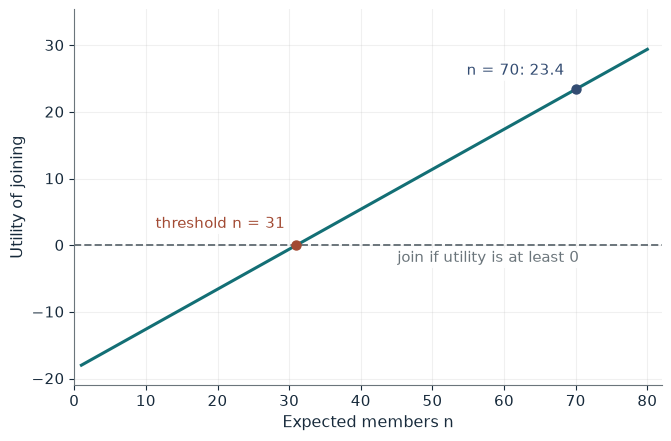

Smallest viable membership n    31
Utility at n = 30               -0.6
Utility at n = 31               0.0
Utility at n = 70               23.4
Viable within 80 organizations  yes

Worked steps:
  1. n - 1 >= (30 - 12) / 0.60 = 30
  2. Smallest integer n = 31
  3. U(30) = 12 + 0.60 x 29 - 30 = -0.6
  4. U(31) = 12 + 0.60 x 30 - 30 = 0.0
  5. U(70) = 12 + 0.60 x 69 - 30 = 23.4

Joining needs 12 + 0.60(n - 1) - 30 >= 0, so n - 1 >= (30 - 12) / 0.60 = 30 and n = 31. At 30 members utility is 12 + 0.60(29) - 30 = -0.6, so a marginal organization stays out; at 31 it is 0.0. At 70 members it is 12 + 0.60(69) - 30 = 23.4.


In [2]:
show(threshold_picture(fee=30, v=0.60))

Change one input, `fee`, and hold the others at the book's values:

In [3]:
sweep(threshold_picture, 'fee', [24, 30, 36], {'v': 0.6}, ['Smallest viable membership n', 'Utility at n = 70'])

fee | Smallest viable membership n | Utility at n = 70
24 | 21 | 29.4
30 | 31 | 23.4
36 | 41 | 17.4


The threshold is 31: at 30 members utility is 12 + 0.60(29) - 30 = -0.6 and at 70 it is 23.4. A fee of 24 cuts the threshold to 21, a larger proportional fall than the fee cut.

## 2. Compatibility can reverse a choice

Tool A has 480 users and stand-alone value 16; tool B has 120 users and value 22; each reachable user adds 0.025.

$$U_A=16+0.025(480)=28 \qquad U_B=22+0.025(120)=25.$$

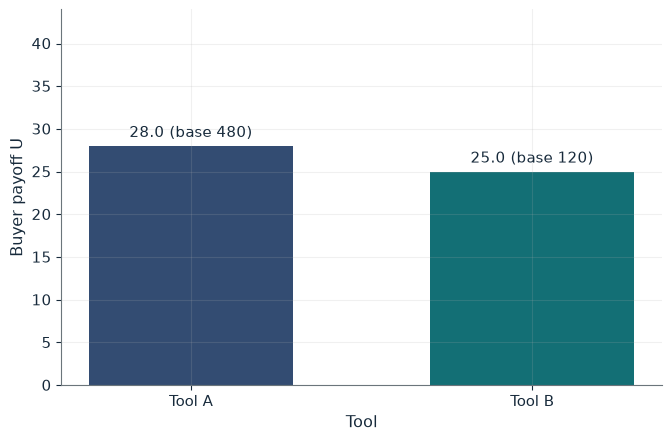

Effective base, A  480
Effective base, B  120
U_A                28.0
U_B                25.0
Choice             Tool A

Worked steps:
  1. Base A = 480 + 0.00 x 120 = 480
  2. Base B = 120 + 0.00 x 480 = 120
  3. U_A = 16 + 0.025 x 480 = 28.0
  4. U_B = 22 + 0.025 x 120 = 25.0
  5. Choice: Tool A

With 0.00 of cross-system interactions carried, A reaches 480 + 0.00(120) = 480 users and B reaches 120 + 0.00(480) = 120. U_A = 16 + 0.025(480) = 28.0 and U_B = 22 + 0.025(120) = 25.0, so the buyer picks Tool A. B overtakes A once 9 theta > 3, that is theta above 1/3.


In [4]:
show(compat_picture(theta=0.0))

Change one input, `theta`, and hold the others at the book's values:

In [5]:
sweep(compat_picture, 'theta', [0.0, 0.3, 0.6, 1.0], {}, ['U_A', 'U_B', 'Choice'])

theta | U_A | U_B | Choice
0.0 | 28.0 | 25.0 | Tool A
0.3 | 28.9 | 28.6 | Tool A
0.6 | 29.8 | 32.2 | Tool B
1.0 | 31.0 | 37.0 | Tool B


Without compatibility A wins 28 to 25. With full compatibility B wins 37 to 31. The reversal needs theta above 1/3, so at 0.30 A still wins narrowly.

## 3. Market tipping: early leads

120 firms; format A has stand-alone value 3, B has 3.3, and each same-format adopter adds 0.012.

$$U_A=3+0.012(75)=3.90 \qquad U_B=3.3+0.012(45)=3.84.$$

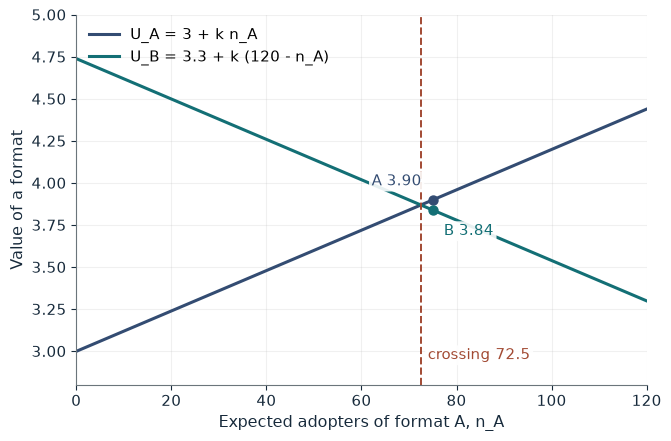

U_A                    3.90
U_B                    3.84
Crossing n_A           72.5
Adoption moves toward  A

Worked steps:
  1. U_A = 3 + 0.012 x 75 = 3.90
  2. U_B = 3.3 + 0.012 x 45 = 3.84
  3. Crossing: 0.024 n_A = 0.3 + 1.44, so n_A = 72.5
  4. Adoption moves toward A

U_A = 3 + 0.012(75) = 3.90 and U_B = 3.3 + 0.012(45) = 3.84, so adoption moves toward A. Setting 3 + 0.012 n_A = 3.3 + 0.012(120 - n_A) gives n_A = 72.5, so A needs at least 73 expected adopters to lead.


In [6]:
show(tipping_picture(n_a=75, k=0.012))

Change one input, `n_a`, and hold the others at the book's values:

In [7]:
sweep(tipping_picture, 'n_a', [70, 73, 75], {'k': 0.012}, ['U_A', 'U_B', 'Adoption moves toward'])

n_a | U_A | U_B | Adoption moves toward
70 | 3.84 | 3.90 | B
73 | 3.876 | 3.864 | A
75 | 3.90 | 3.84 | A


The lines cross at 72.5, so A needs 73 expected adopters to lead. With portability (k = 0.004) the crossing moves to 97.5 and the 75 to 45 lead no longer tips the market.

## 4. Two-sided platform: same receipts, different participation

150 buyers and 30 sellers; a buyer values 3 + 0.40 per seller, a seller 0.20 per buyer; serving costs 2 and 8.

$$3+0.40(30)-9=6, \qquad 0.20(150)-18=12.$$

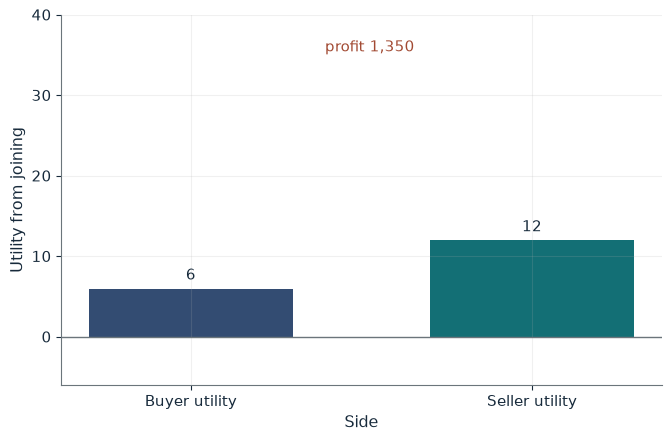

Buyer fee           9
Seller fee          18
Buyer utility       6
Seller utility      12
Active buyers       150
Active sellers      30
Projected receipts  1,890
Profit              1,350

Worked steps:
  1. Buyer: 3 + 0.40 x 30 - 9 = 6
  2. Seller: 0.20 x 150 - 18 = 12
  3. Projected receipts: 150(9) + 30(18) = 1,890
  4. Profit: 150(9 - 2) + 30(18 - 8) = 1,050 + 300 = 1,350

Buyer utility is 3 + 0.40(30) - 9 = 6 and seller utility is 0.20(150) - 18 = 12. Both sides join. Projected receipts are 150(9) + 30(18) = 1,890, and profit is 150(9 - 2) + 30(18 - 8) = 1,050 + 300 = 1,350.


In [8]:
show(fees_picture(alloc='9/18'))

Change one input, `alloc`, and hold the others at the book's values:

In [9]:
sweep(fees_picture, 'alloc', ['9/18', '11/8', '13/-2', '16/-17'], {}, ['Buyer utility', 'Seller utility', 'Projected receipts', 'Profit'])

alloc | Buyer utility | Seller utility | Projected receipts | Profit
9/18 | 6 | 12 | 1,890 | 1,350
11/8 | 4 | 22 | 1,890 | 1,350
13/-2 | 2 | 32 | 1,890 | 1,350
16/-17 | -1 | 17 | 1,890 | -750


Every pair projects 1,890 of receipts, but at buyer fee 16 buyer utility is -1, buyers leave and profit falls from 1,350 to -750.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

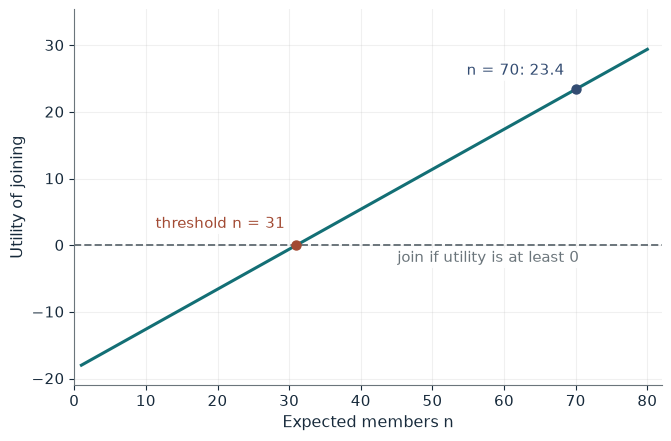

Smallest viable membership n    31
Utility at n = 30               -0.6
Utility at n = 31               0.0
Utility at n = 70               23.4
Viable within 80 organizations  yes

Worked steps:
  1. n - 1 >= (30 - 12) / 0.60 = 30
  2. Smallest integer n = 31
  3. U(30) = 12 + 0.60 x 29 - 30 = -0.6
  4. U(31) = 12 + 0.60 x 30 - 30 = 0.0
  5. U(70) = 12 + 0.60 x 69 - 30 = 23.4

Joining needs 12 + 0.60(n - 1) - 30 >= 0, so n - 1 >= (30 - 12) / 0.60 = 30 and n = 31. At 30 members utility is 12 + 0.60(29) - 30 = -0.6, so a marginal organization stays out; at 31 it is 0.0. At 70 members it is 12 + 0.60(69) - 30 = 23.4.


In [10]:
show(threshold_picture(fee=30, v=0.60))

## Practice

**1.** With a fee of 36 and 0.60 per member, what is the smallest viable membership?

<details><summary>Answer</summary>

12 + 0.60(n - 1) - 36 >= 0 gives n - 1 >= 40, so n = 41.

</details>

**2.** At theta = 0.30, which tool wins?

<details><summary>Answer</summary>

U_A = 16 + 0.025(516) = 28.9 and U_B = 22 + 0.025(264) = 28.6, so A wins narrowly.

</details>

**3.** Where do the format lines cross when k = 0.004?

<details><summary>Answer</summary>

3 + 0.004 n = 3.3 + 0.004(120 - n) gives 0.008 n = 0.78, so n = 97.5.

</details>